# Análise Preditiva — Deliverable 2
## Quanto as empresas vão usar e gastar com IA nos próximos seis meses?

**DAMA Intelligence** · Ana Luiza Proença, Gustavo Gomes, Kaique Lira e Ricardo Matteo · Ciência de Dados e Negócios, ESPM, 4º semestre, 2026

Este notebook constrói, valida e aplica modelos de **previsão mensal** para as 18 empresas da base:

1. **Demanda de IA:** requisições por mês, de agosto de 2026 a janeiro de 2027.
2. **Custo de consumo:** tokens nas APIs e plataformas cobradas por uso, convertidos em reais.
3. **Orçamento:** o custo previsto comparado com o orçado, empresa a empresa.

A previsão abastece o planejamento de licenças da [Pesquisa Operacional](../Pesquisa%20Operacional/), que hoje usa o orçamento médio do passado, e os alertas de gestão do DAMA.

## 1. Do Deliverable 1 ao Deliverable 2

No D1, a pergunta era **quem vai ter um incidente de segurança no uso de IA**. A versão corrigida (`Deliverable1/AnalisePreditiva/DAMAAnalisePreditiva1_corrigido.ipynb`) atende ao feedback da pré-avaliação: diagnóstico da base, baseline, métricas para classe rara, tratamento do desbalanceamento e validação cruzada estratificada repetida. Ela mostra que:

- com 67 casos em 2.356 colaboradores, o melhor modelo fica pouco acima do sorteio;
- o pouco sinal que existe vem da **empresa**, porque empresas menores têm mais incidentes por colaborador, e não do comportamento individual;
- cursos e uso de tokens não ajudam a prever incidentes. A Estatística Multivariada chegou à mesma conclusão sobre a hipótese H2.

Um modelo assim não sustenta decisão sobre pessoas. Por isso o D2 muda para uma pergunta que a base responde e que o produto precisa: **qual será a demanda e o custo de IA nos próximos meses**. É a parte preditiva do FinOps de IA, e alimenta o orçamento da Pesquisa Operacional.

## 2. Configuração

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

DADOS = Path('../../Deliverable1/machine-learning-ia/Data/csv')
SAIDA = Path('resultados'); SAIDA.mkdir(exist_ok=True)
FIG = Path('figuras'); FIG.mkdir(exist_ok=True)
SEED = 42
CAMBIO = 5.50                                   # R$ por US$, a mesma premissa da Pesquisa Operacional
MESES = pd.period_range('2025-06', '2026-07', freq='M')
FUTURO = pd.period_range('2026-08', '2027-01', freq='M')
ORIGENS = pd.period_range('2025-12', '2026-06', freq='M')   # origens do backtest
H = 3                                            # horizonte avaliado no backtest
FERIAS = (12, 1, 7)                              # dezembro, janeiro e julho
MIN_TENDENCIA = 6                                # meses mínimos de histórico para estimar uma tendência

AZUL, LARANJA, VERDE, AMARELO, MAGENTA = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4'
CINZA = '#8f8e89'
TINTA, TINTA2, GRADE, FUNDO = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': FUNDO, 'axes.facecolor': FUNDO, 'axes.edgecolor': GRADE, 'axes.labelcolor': TINTA2,
    'xtick.color': TINTA2, 'ytick.color': TINTA2, 'text.color': TINTA, 'axes.grid': True, 'grid.color': GRADE,
    'grid.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'legend.frameon': False
})
inicio = time.time()

## 3. Dados e diagnóstico das séries

In [2]:
ler = lambda nome, **kw: pd.read_csv(DADOS / f'{nome}.csv', **kw)
uso = ler('ai_usage_logs', usecols=['timestamp', 'company_id', 'ai_tool_id', 'model_id', 'cost_center', 'request_count', 'input_tokens', 'output_tokens'])
comp, tools, models = ler('companies'), ler('ai_tools'), ler('ai_models')
fat, orc = ler('ai_billing'), ler('ai_budgets')
uso['mes'] = pd.to_datetime(uso.timestamp).dt.to_period('M')
consumo_ids = set(tools.loc[tools.licensing_type.str.startswith('Consumo'), 'ai_tool_id'])

demanda = uso.groupby(['company_id', 'mes']).request_count.sum().unstack(fill_value=0).reindex(columns=MESES, fill_value=0)
uc = uso[uso.ai_tool_id.isin(consumo_ids)].copy()
uc['tokens'] = uc.input_tokens + uc.output_tokens
tokens = uc.groupby(['company_id', 'mes']).tokens.sum().unstack(fill_value=0).reindex(columns=MESES, fill_value=0)

def inicio_serie(s):
    return s[s > 0].index.min()
diag = pd.DataFrame({
    'empresa': comp.set_index('company_id').company_name,
    'setor': comp.set_index('company_id').industry,
    'inicio_do_uso': demanda.apply(inicio_serie, axis=1).astype(str),
    'meses_com_uso': (demanda > 0).sum(1),
    'requisicoes_jul2026': demanda[MESES[-1]],
    'variacao_jan_jul_2026': demanda[MESES[-1]] / demanda[pd.Period('2026-01', 'M')].replace(0, np.nan) - 1,
    'usa_ferramenta_de_consumo': (tokens.sum(1) > 0).reindex(comp.company_id).fillna(False).values,
})
diag.to_csv(SAIDA / 'diagnostico_series.csv')
diag.round(3)

,empresa,setor,inicio_do_uso,meses_com_uso,requisicoes_jul2026,variacao_jan_jul_2026,usa_ferramenta_de_consumo
company_id,,,,,,,
C01,NexoCode Solucoes,Tecnologia / Desenvolvimento de Software,2025-06,14,372716,0.447,True
C02,Vortice Software,Tecnologia / Desenvolvimento de Software,2025-06,14,149743,0.435,True
C03,Piloto Digital Sistemas,Tecnologia / Desenvolvimento de Software,2025-08,12,22227,0.421,True
C04,Cronos Tech Labs,Tecnologia / Desenvolvimento de Software,2025-06,14,64093,0.015,True
C05,ByteFlow Engenharia de Software,Tecnologia / Desenvolvimento de Software,2025-12,8,11476,0.226,False
C06,Banco Alterosa S.A.,Financeiro,2025-07,13,29355,0.637,False
C07,Capital Sul Investimentos,Financeiro,2026-02,6,5166,NaN,False
C08,Fincredi Solucoes Financeiras,Financeiro,2025-09,11,5066,0.878,False
C09,Metalurgica Vale Forte,Industria,2025-11,9,6629,0.127,False


**Leitura do diagnóstico**

- **Início do uso diferente por empresa.** Cinco empresas começam depois de junho de 2025, e duas só em 2026: TextilNorte em abril e ServPro em março. Cada série é modelada **a partir do primeiro mês com uso**. Os zeros anteriores não são queda de demanda, são ausência de adoção.
- **Histórico curto:** no máximo 14 meses. Não há dois ciclos anuais completos, então um modelo sazonal clássico (Holt-Winters) não pode ser estimado empresa a empresa.
- **Só 8 das 18 empresas usam ferramentas de consumo** (APIs e plataformas). O custo de consumo é previsto só para elas.
- **Faturas ausentes:** parte dos lançamentos de consumo não existe em `ai_billing`, simulando falha de integração com o provedor. Por isso o custo de consumo vem dos **logs de uso**, que estão completos, multiplicados pelo preço por token de `ai_models`. A seção 7 mede as faturas ausentes e confere o cálculo contra as que existem.

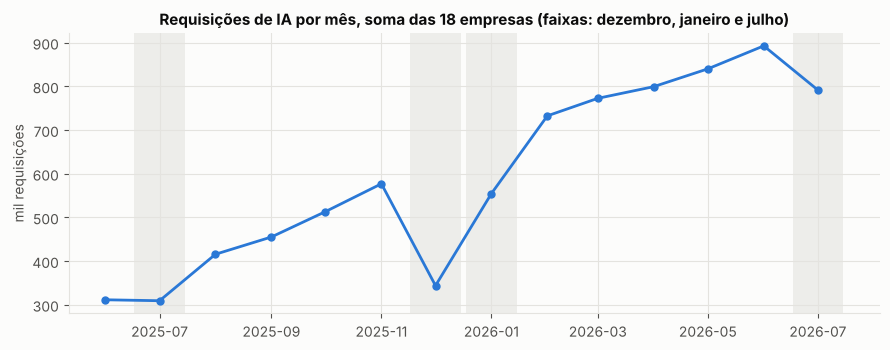

In [3]:
total = demanda.sum()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot([p.to_timestamp() for p in MESES], total / 1e3, color=AZUL, marker='o', ms=5)
for p in MESES:
    if p.month in FERIAS:
        ax.axvspan(p.to_timestamp() - pd.Timedelta(days=14), p.to_timestamp() + pd.Timedelta(days=14), color=GRADE, alpha=0.6, lw=0)
ax.set(title='Requisições de IA por mês, soma das 18 empresas (faixas: dezembro, janeiro e julho)', ylabel='mil requisições')
fig.tight_layout(); fig.savefig(FIG / 'fig1_demanda_total.png', dpi=150); plt.show()

A série total sobe de forma quase linear e cai nos meses de férias: dezembro de 2025, janeiro e julho de 2026. Esse padrão define os modelos candidatos: **tendência + efeito de calendário**.

## 4. Modelos candidatos

| Modelo | Como prevê | Por que testar |
|---|---|---|
| **Ingênuo** | Repete o último mês | Referência mínima: um modelo útil tem de superá-lo |
| **Média móvel de 3 meses** | Média dos três últimos meses | Suaviza ruído, mas não acompanha tendência |
| **Holt amortecido** | Suavização exponencial com tendência amortecida, em log | Clássico para séries curtas com tendência |
| **Tendência + férias** | Regressão linear por empresa: tempo + indicador de mês de férias | Captura tendência e calendário com poucos parâmetros |
| **Tendência × fatores comuns** | Tendência linear por empresa multiplicada por um fator de calendário (dez, jan, jul) **comum a todas as empresas** | Cada empresa viu um único dezembro. Estimar o fator com as 18 empresas juntas é mais estável |
| **Gradient boosting global** | Um só modelo de árvores para todas as empresas, prevendo a variação em relação ao último mês a partir das defasagens, do calendário e do horizonte | Abordagem de aprendizado de máquina para séries, para comparar com os modelos estatísticos |

**Fator de calendário comum.** Para cada mês de férias, o fator é a mediana, entre as empresas, da razão entre o valor observado e a tendência da própria empresa. A conta é repetida três vezes, reestimando a tendência sem o efeito das férias. Só entram meses de férias **já observados até a origem** da previsão: antes do primeiro janeiro da base, o fator de janeiro é 1.

**Séries curtas.** Uma tendência estimada com menos de 6 meses extrapola qualquer oscilação da adoção. A TextilNorte, por exemplo, tem 4 meses, com pico em maio e queda depois. Nesses casos, os modelos de tendência usam o **nível médio dos últimos 3 meses**, sem o efeito do calendário, multiplicado pelo calendário dos meses previstos.

In [4]:
def calendario(periodos):
    return np.array([[int(p.month == m) for m in FERIAS] for p in periodos])

def fatores_comuns(series, origem):
    """Fatores multiplicativos de dez, jan e jul estimados com todas as séries até a origem."""
    F = np.ones(3)
    for _ in range(3):
        razoes = {m: [] for m in range(3)}
        for s in series:
            s = s[s.index <= origem]
            if len(s) < 4:
                continue
            t = np.arange(len(s)); d = calendario(s.index)
            ajuste = s.values / np.exp(d @ np.log(F))
            b = np.polyfit(t, ajuste, 1); tend = np.polyval(b, t)
            for j in range(3):
                for i in np.where(d[:, j] == 1)[0]:
                    if tend[i] > 0:
                        razoes[j].append(s.values[i] / tend[i])
        F = np.array([np.median(razoes[j]) if razoes[j] else 1.0 for j in range(3)])
    return F

def prever(s, h, metodo, F=None):
    """s: série de uma empresa (a partir do início do uso) até a origem; devolve h previsões."""
    y = s.values.astype(float); fut = pd.period_range(s.index[-1] + 1, periods=h, freq='M')
    t, tf = np.arange(len(y)), np.arange(len(y), len(y) + h)
    if metodo == 'Ingênuo' or (len(y) < 4 and metodo != 'Média móvel 3m'):
        return np.repeat(y[-1], h)
    if metodo == 'Média móvel 3m':
        return np.repeat(y[-3:].mean(), h)
    if metodo == 'Holt amortecido':
        m = ExponentialSmoothing(np.log(np.maximum(y, 1)), trend='add', damped_trend=True, initialization_method='estimated').fit()
        return np.exp(m.forecast(h))
    if metodo in ('Tendência + férias', 'Tendência × fatores comuns') and len(y) < MIN_TENDENCIA:
        # histórico curto demais para uma tendência: nível dos últimos 3 meses, sem o efeito do calendário, vezes o calendário futuro
        Fu = F if F is not None else np.ones(3)
        nivel = (y[-3:] / np.exp(calendario(s.index[-3:]) @ np.log(Fu))).mean()
        return nivel * np.exp(calendario(fut) @ np.log(Fu))
    if metodo == 'Tendência + férias':
        fer = np.isin([p.month for p in s.index], FERIAS).astype(int)
        X = np.c_[np.ones_like(t), t] if fer.sum() == 0 else np.c_[np.ones_like(t), t, fer]
        b = np.linalg.lstsq(X, y, rcond=None)[0]
        ff = np.isin([p.month for p in fut], FERIAS).astype(int)
        Xf = np.c_[np.ones(h), tf] if fer.sum() == 0 else np.c_[np.ones(h), tf, ff]
        return np.maximum(Xf @ b, 0)
    if metodo == 'Tendência × fatores comuns':
        ajuste = y / np.exp(calendario(s.index) @ np.log(F))
        b = np.polyfit(t, ajuste, 1)
        return np.maximum(np.polyval(b, tf), 0) * np.exp(calendario(fut) @ np.log(F))
    raise ValueError(metodo)

**Gradient boosting global.** Cada linha de treino é uma empresa num mês *t* com horizonte *k* de 1 a 3. O alvo é log(*y*<sub>t+k</sub> / *y*<sub>t</sub>). As variáveis são:

- as variações recentes: log(*y*<sub>t</sub>/*y*<sub>t−1</sub>), log(*y*<sub>t</sub>/*y*<sub>t−2</sub>) e log(*y*<sub>t</sub>/*y*<sub>t−3</sub>);
- o horizonte *k*;
- os indicadores de férias do mês *t* e do mês *t*+*k*;
- os meses desde o início do uso.

Só entram linhas cujo alvo já era conhecido na origem.

In [5]:
def linhas_globais(series_dict, ate):
    L = []
    for c, s in series_dict.items():
        s = s[s.index <= ate]
        v = np.maximum(s.values.astype(float), 1)
        for i in range(3, len(s)):
            for k in range(1, H + 1):
                alvo = np.log(v[i + k] / v[i]) if i + k < len(s) else np.nan
                p_alvo = s.index[i] + k
                L.append(dict(empresa=c, origem=s.index[i], k=k, alvo=alvo,
                              d1=np.log(v[i] / v[i - 1]), d2=np.log(v[i] / v[i - 2]), d3=np.log(v[i] / v[i - 3]),
                              fer_t=int(s.index[i].month in FERIAS), fer_alvo=int(p_alvo.month in FERIAS),
                              dez_alvo=int(p_alvo.month == 12), idade=i, nivel=v[i]))
    return pd.DataFrame(L)

VARS_GB = ['k', 'd1', 'd2', 'd3', 'fer_t', 'fer_alvo', 'dez_alvo', 'idade']

def prever_global(series_dict, origem):
    """Treina com o que se conhecia na origem e prevê h = 1..H para cada empresa."""
    L = linhas_globais(series_dict, origem)
    tr = L[L.alvo.notna()]
    gb = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=8, min_samples_leaf=10, random_state=SEED)
    gb.fit(tr[VARS_GB], tr.alvo)
    ult = L[L.origem == origem]
    out = {}
    for c, g in ult.groupby('empresa'):
        g = g.sort_values('k')
        out[c] = g.nivel.values * np.exp(gb.predict(g[VARS_GB]))
    return out

## 5. Validação: backtest com origem móvel

A validação imita o uso real. Em cada **origem** de dezembro de 2025 a junho de 2026, os modelos veem só os dados até aquele mês e preveem os 1 a 3 meses seguintes, que são comparados com o que aconteceu. São 7 origens, 18 empresas e 3 horizontes, sem nenhum dado do futuro no ajuste.

**Métricas**
- **WAPE (principal):** erro absoluto total dividido pela demanda total. É uma porcentagem, comparável entre empresas grandes e pequenas, e não explode em séries com valores baixos.
- **MAE:** erro médio em requisições.
- **sMAPE:** erro percentual simétrico, dando o mesmo peso a cada empresa.
- **Viés:** soma dos erros sobre a soma do real. Positivo quer dizer que o modelo superestima.

In [6]:
METODOS = ['Ingênuo', 'Média móvel 3m', 'Holt amortecido', 'Tendência + férias', 'Tendência × fatores comuns', 'Gradient boosting global']

def series_validas(tabela):
    return {c: tabela.loc[c][tabela.loc[c].index >= inicio_serie(tabela.loc[c])] for c in tabela.index if tabela.loc[c].sum() > 0}

def backtest(tabela, metodos=METODOS):
    series = series_validas(tabela)
    linhas = []
    for o in ORIGENS:
        F = fatores_comuns(list(series.values()), o)
        glob = prever_global(series, o) if 'Gradient boosting global' in metodos else {}
        for c, s in series.items():
            hist = s[s.index <= o]
            if len(hist) < 3:
                continue
            for metodo in metodos:
                f = glob.get(c) if metodo == 'Gradient boosting global' else prever(hist, H, metodo, F)
                if f is None:
                    f = prever(hist, H, 'Ingênuo')
                for k in range(1, H + 1):
                    alvo = o + k
                    if alvo > MESES[-1]:
                        continue
                    linhas.append(dict(origem=str(o), empresa=c, metodo=metodo, h=k, mes=str(alvo), real=s[alvo], previsto=float(f[k - 1])))
    return pd.DataFrame(linhas)

def resumo_erros(bt):
    def m(g):
        e = g.previsto - g.real
        return pd.Series({'WAPE': e.abs().sum() / g.real.sum(), 'MAE': e.abs().mean(),
                          'sMAPE': (2 * e.abs() / (g.real.abs() + g.previsto.abs()).replace(0, np.nan)).mean(),
                          'viés': e.sum() / g.real.sum(), 'n': len(g)})
    por_h = bt.groupby(['metodo', 'h']).apply(m, include_groups=False).unstack('h')
    geral = bt.groupby('metodo').apply(m, include_groups=False)
    return por_h, geral

bt_dem = backtest(demanda)
por_h, geral = resumo_erros(bt_dem)
tabela_val = pd.concat({'WAPE h=1': por_h['WAPE'][1], 'WAPE h=2': por_h['WAPE'][2], 'WAPE h=3': por_h['WAPE'][3],
                        'WAPE geral': geral['WAPE'], 'sMAPE geral': geral['sMAPE'], 'viés': geral['viés'], 'MAE': geral['MAE'], 'previsões': geral['n']}, axis=1)
tabela_val = tabela_val.loc[METODOS].sort_values('WAPE geral')
bt_dem.to_csv(SAIDA / 'backtest_demanda.csv', index=False)
tabela_val.to_csv(SAIDA / 'metricas_backtest_demanda.csv')
tabela_val.round(3)

,WAPE h=1,WAPE h=2,WAPE h=3,WAPE geral,sMAPE geral,viés,MAE,previsões
metodo,,,,,,,,
Tendência × fatores comuns,0.058,0.056,0.061,0.058,0.103,-0.011,3116.838,262.0
Tendência + férias,0.068,0.073,0.084,0.074,0.123,-0.057,3999.325,262.0
Gradient boosting global,0.152,0.164,0.184,0.165,0.222,-0.068,8878.058,262.0
Ingênuo,0.128,0.186,0.224,0.175,0.218,-0.144,9408.626,262.0
Holt amortecido,0.136,0.186,0.226,0.178,0.235,-0.084,9581.293,262.0
Média móvel 3m,0.160,0.220,0.273,0.212,0.248,-0.198,11405.761,262.0


- **Tendência × fatores comuns** erra 5,8% em média: de 5,6% a 6,1% de 1 a 3 meses à frente, com viés de −1,1%. É menos da metade do erro do ingênuo, que vai de 12,8% a 22,4%.
- **Os modelos sem calendário** (ingênuo, média móvel e Holt) erram mais a cada mês à frente: não sabem que dezembro e janeiro caem.
- **O gradient boosting global** (16,5%) perde para os modelos estatísticos. Com 14 meses por empresa, falta histórico para aprender a dinâmica a partir das defasagens, e os modelos com estrutura explícita (tendência e calendário) levam vantagem.

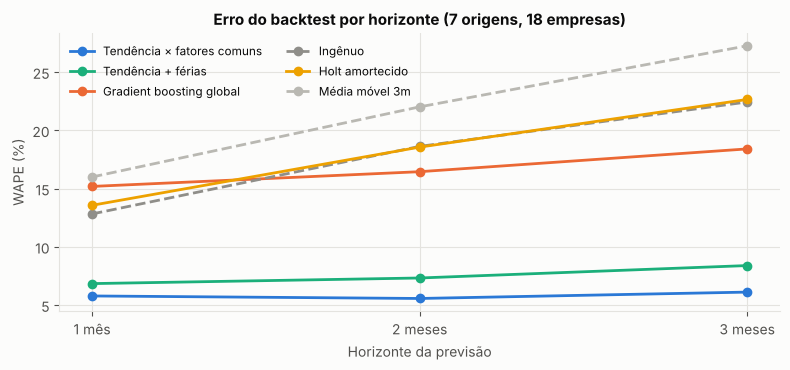

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ordem = tabela_val.index.tolist()
cores = {m: c for m, c in zip(METODOS, [CINZA, '#b9b8b2', AMARELO, VERDE, AZUL, LARANJA])}
x = np.arange(1, H + 1)
for m in ordem:
    ax.plot(x, por_h.loc[m, 'WAPE'].values * 100, marker='o', ms=6, color=cores[m], label=m,
            ls='--' if m in ('Ingênuo', 'Média móvel 3m') else '-')
ax.set_xticks(x, ['1 mês', '2 meses', '3 meses'])
ax.set(title='Erro do backtest por horizonte (7 origens, 18 empresas)', ylabel='WAPE (%)', xlabel='Horizonte da previsão')
ax.legend(loc='upper left', fontsize=8.5, ncol=2)
fig.tight_layout(); fig.savefig(FIG / 'fig2_backtest_horizonte.png', dpi=150); plt.show()

### Erro por empresa e por mês

O erro agregado pode esconder empresas mal previstas. A tabela abaixo mostra o WAPE do modelo escolhido por empresa, e a seguinte, por mês previsto, onde aparecem os meses de férias.

In [8]:
ESCOLHIDO = tabela_val.index[0]
print('Modelo escolhido (menor WAPE no backtest):', ESCOLHIDO)
sel = bt_dem[bt_dem.metodo == ESCOLHIDO]
wape = lambda g: (g.previsto - g.real).abs().sum() / g.real.sum()
por_empresa = sel.groupby('empresa').apply(wape, include_groups=False).rename('WAPE').to_frame().join(comp.set_index('company_id').company_name)
ing = bt_dem[bt_dem.metodo == 'Ingênuo'].groupby('empresa').apply(wape, include_groups=False).rename('WAPE ingênuo')
por_empresa = por_empresa.join(ing).sort_values('WAPE')
por_mes = pd.concat({ESCOLHIDO: sel.groupby('mes').apply(wape, include_groups=False),
                     'Ingênuo': bt_dem[bt_dem.metodo == 'Ingênuo'].groupby('mes').apply(wape, include_groups=False)}, axis=1)
por_empresa.to_csv(SAIDA / 'erro_por_empresa.csv'); por_mes.to_csv(SAIDA / 'erro_por_mes.csv')
display(por_empresa.round(3))
por_mes.round(3).T

Modelo escolhido (menor WAPE no backtest): Tendência × fatores comuns


,WAPE,company_name,WAPE ingênuo
empresa,,,
C06,0.038,Banco Alterosa S.A.,0.177
C01,0.044,NexoCode Solucoes,0.181
C02,0.047,Vortice Software,0.159
C13,0.061,Lojas Formosa,0.106
C17,0.062,Ideia Fresca Marketing,0.183
C18,0.074,Estrela Marketing Digital,0.204
C04,0.080,Cronos Tech Labs,0.137
C12,0.081,Compra Certa Varejo,0.195
C14,0.084,MercadoPrime E-commerce,0.188


mes,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07
Tendência × fatores comuns,0.139,0.099,0.074,0.055,0.034,0.046,0.041
Ingênuo,0.378,0.381,0.292,0.149,0.100,0.107,0.077


- **Por empresa:** o erro é baixo nas grandes (3,8% a 4,7% em Banco Alterosa, NexoCode e Vortice) e maior nas pequenas, onde o ruído de cada colaborador pesa mais.
- **TextilNorte (60,5%)** começou a usar IA em abril de 2026. Nas origens do backtest, tinha de 1 a 3 meses de histórico, e nenhum método previu a rampa de adoção.
- **Por mês:** o maior erro é janeiro de 2026 (13,9%). Era o primeiro janeiro da base, e nenhum modelo podia conhecer o tamanho da queda. De fevereiro em diante, o erro fica entre 3,4% e 9,9%.

### Intervalos de previsão

A previsão vem com uma faixa de 80%. Ela sai dos **erros do próprio backtest**: o quantil 10% e o quantil 90% de log(real/previsto), por horizonte.

Para verificar se a faixa é honesta, ela é **calibrada nas origens de dez/2025 a mar/2026** e **testada nas origens de abr a jun/2026**. Se a cobertura no teste ficar perto de 80%, a faixa é confiável.

In [9]:
sel = sel.assign(erro_log=np.log(np.maximum(sel.real, 1) / np.maximum(sel.previsto, 1)))
calib = sel[sel.origem <= '2026-03']; aval = sel[sel.origem >= '2026-04']
q = calib.groupby('h').erro_log.quantile([0.1, 0.9]).unstack()
aval = aval.join(q, on='h')
aval['dentro'] = (aval.erro_log >= aval[0.1]) & (aval.erro_log <= aval[0.9])
cobertura = aval.groupby('h').dentro.mean()
print('Cobertura da faixa de 80% nas origens de abr a jun/2026, por horizonte:', cobertura.round(2).to_dict(), '| geral:', round(aval.dentro.mean(), 2))
q_final = sel.groupby('h').erro_log.quantile([0.1, 0.9]).unstack()   # para o futuro, todos os erros
q_final

Cobertura da faixa de 80% nas origens de abr a jun/2026, por horizonte: {1: 0.92, 2: 0.85, 3: 0.88} | geral: 0.89


,0.1,0.9
h,,
1,-0.138083,0.157297
2,-0.091354,0.195040
3,-0.089230,0.268736


A faixa cobre **89% dos casos** fora da calibração (92%, 85% e 88% de 1 a 3 meses), um pouco acima dos 80% nominais. Ela é levemente conservadora, o que é preferível quando a previsão vai virar orçamento.

## 6. Previsão da demanda: agosto de 2026 a janeiro de 2027

O modelo escolhido é reajustado com todos os 14 meses. O backtest valida até 3 meses à frente. De 4 a 6 meses, a faixa é **alargada** proporcionalmente à raiz do horizonte, a partir dos quantis de 3 meses. É uma premissa explícita: o histórico não permite validar diretamente horizontes mais longos.

In [10]:
def faixa(h):
    base = q_final.loc[min(h, H)]
    esc = np.sqrt(h / H) if h > H else 1.0
    return base[0.1] * esc, base[0.9] * esc

def prever_futuro(tabela, metodo):
    series = series_validas(tabela)
    F = fatores_comuns(list(series.values()), MESES[-1])
    linhas = []
    for c, s in series.items():
        if metodo == 'Gradient boosting global':
            raise ValueError('o horizonte de 6 meses não foi validado para o modelo global')
        f = prever(s, len(FUTURO), metodo, F)
        for h, (p, v) in enumerate(zip(FUTURO, f), start=1):
            lo, hi = faixa(h)
            linhas.append(dict(empresa=c, mes=str(p), h=h, previsto=v, p10=v * np.exp(lo), p90=v * np.exp(hi)))
    return pd.DataFrame(linhas), F

prev_dem, F_dem = prever_futuro(demanda, ESCOLHIDO)
print('Fatores de calendário estimados (dez, jan, jul):', np.round(F_dem, 3))
prev_dem.to_csv(SAIDA / 'previsao_demanda_ago2026_jan2027.csv', index=False)
tab = prev_dem.pivot(index='empresa', columns='mes', values='previsto').round(0).astype(int)
tab.insert(0, 'jul/2026 (real)', demanda[MESES[-1]].reindex(tab.index))
tab.join(comp.set_index('company_id').company_name)

Fatores de calendário estimados (dez, jan, jul): [0.581 0.812 0.856]


,jul/2026 (real),2026-08,2026-09,2026-10,2026-11,2026-12,2027-01,company_name
empresa,,,,,,,,
C01,372716,464583,486695,508807,530920,321062,467114,NexoCode Solucoes
C02,149743,186334,195293,204253,213213,128982,187718,Vortice Software
C03,22227,29715,31344,32973,34602,21034,30748,Piloto Digital Sistemas
C04,64093,76863,77929,78994,80060,47097,66753,Cronos Tech Labs
C05,11476,15184,15648,16112,16575,9892,14215,ByteFlow Engenharia de Software
C06,29355,35384,37167,38949,40731,24681,35975,Banco Alterosa S.A.
C07,5166,5836,5862,5889,5915,3450,4847,Capital Sul Investimentos
C08,5066,5339,5640,5941,6241,3798,5557,Fincredi Solucoes Financeiras
C09,6629,7437,7419,7401,7383,4276,5967,Metalurgica Vale Forte


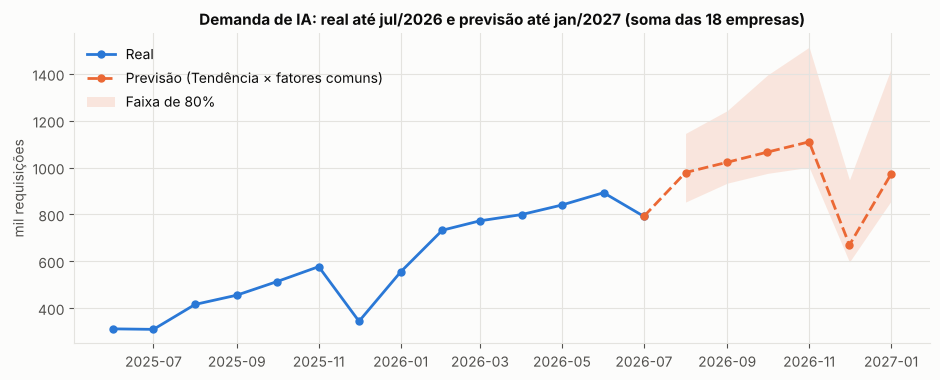

In [11]:
tot_hist = demanda.sum()
tot_prev = prev_dem.groupby('mes').previsto.sum()
# faixa do total: soma das faixas das empresas (conservadora, supõe erros perfeitamente correlacionados)
tot_lo, tot_hi = prev_dem.groupby('mes').p10.sum(), prev_dem.groupby('mes').p90.sum()
fig, ax = plt.subplots(figsize=(9.5, 3.9))
xh = [p.to_timestamp() for p in MESES]; xf = [pd.Period(m, 'M').to_timestamp() for m in tot_prev.index]
ax.plot(xh, tot_hist / 1e3, color=AZUL, marker='o', ms=5, label='Real')
ax.plot([xh[-1]] + xf, np.r_[tot_hist.iloc[-1], tot_prev.values] / 1e3, color=LARANJA, marker='o', ms=5, ls='--', label=f'Previsão ({ESCOLHIDO})')
ax.fill_between(xf, tot_lo / 1e3, tot_hi / 1e3, color=LARANJA, alpha=0.15, lw=0, label='Faixa de 80%')
ax.set(title='Demanda de IA: real até jul/2026 e previsão até jan/2027 (soma das 18 empresas)', ylabel='mil requisições')
ax.legend(loc='upper left')
fig.tight_layout(); fig.savefig(FIG / 'fig3_previsao_total.png', dpi=150); plt.show()

- A demanda total deve passar de **792 mil requisições em julho**, mês de férias, para **979 mil em agosto**, e chegar a **1,11 milhão em novembro**.
- Em **dezembro**, cai para **670 mil**, e volta a **972 mil em janeiro**.
- Os fatores de calendário estimados são 0,58 para dezembro, 0,81 para janeiro e 0,86 para julho. Foram aprendidos com um único ciclo por empresa. Por isso, as faixas de dezembro (597 a 947 mil) e de janeiro (857 mil a 1,42 milhão) são as mais largas.

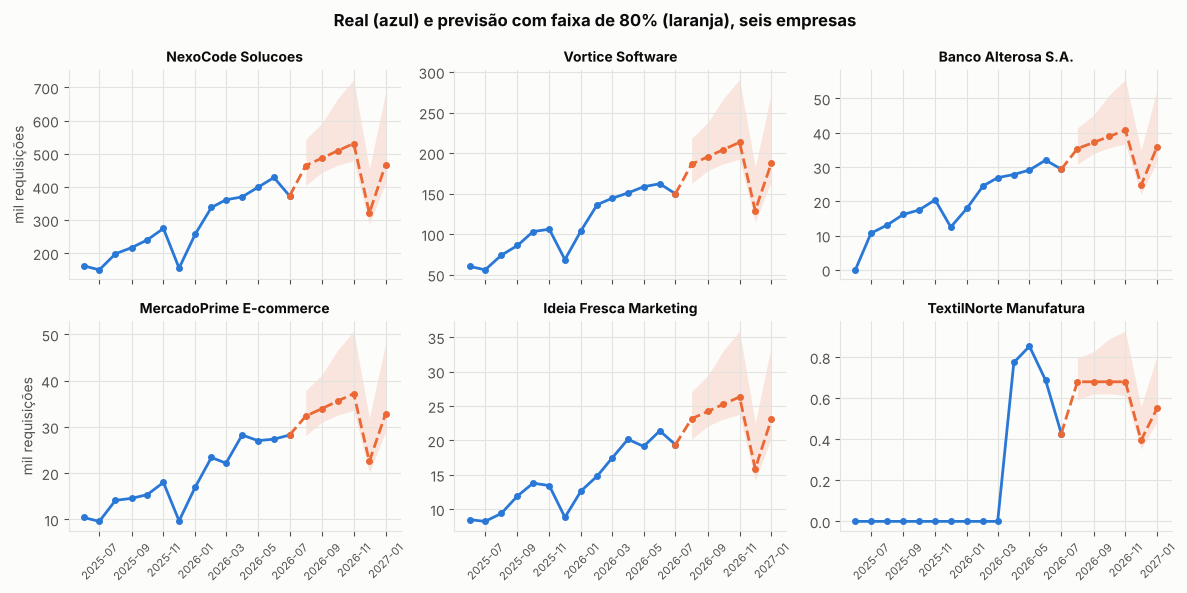

In [12]:
destaque = ['C01', 'C02', 'C06', 'C14', 'C17', 'C11']
fig, eixos = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, c in zip(eixos.flat, destaque):
    s = demanda.loc[c]; p = prev_dem[prev_dem.empresa == c]
    ax.plot(xh, s / 1e3, color=AZUL, marker='o', ms=4)
    ax.plot([xh[-1]] + xf, np.r_[s.iloc[-1], p.previsto.values] / 1e3, color=LARANJA, ls='--', marker='o', ms=4)
    ax.fill_between(xf, p.p10 / 1e3, p.p90 / 1e3, color=LARANJA, alpha=0.15, lw=0)
    ax.set_title(comp.set_index('company_id').company_name[c], fontsize=10)
    ax.tick_params(axis='x', labelrotation=45, labelsize=8)
for ax in eixos[:, 0]:
    ax.set_ylabel('mil requisições')
fig.suptitle('Real (azul) e previsão com faixa de 80% (laranja), seis empresas', fontweight='bold')
fig.tight_layout(); fig.savefig(FIG / 'fig4_previsao_empresas.png', dpi=150); plt.show()

## 7. Custo de consumo (APIs e plataformas)

O custo de consumo é tokens × preço por token. O preço depende do **mix de modelos** de cada empresa. Por exemplo, o claude-opus-4 custa 100 vezes o gpt-4o-mini por token de entrada. O preço médio por token da empresa é medido nos últimos três meses (mai a jul/2026). O mesmo backtest escolhe o modelo de previsão dos tokens.

Antes, uma conferência: o custo calculado pelos logs bate com as faturas?

In [13]:
precos = models.set_index('model_id')[['input_price_usd_per_1k_tokens', 'output_price_usd_per_1k_tokens']]
uc = uc.join(precos, on='model_id')
uc['custo_usd'] = uc.input_tokens / 1000 * uc.input_price_usd_per_1k_tokens + uc.output_tokens / 1000 * uc.output_price_usd_per_1k_tokens
uc['centro'] = uc.cost_center.fillna('SEM_CC')
chave = ['company_id', 'ai_tool_id', 'model_id', 'centro', 'mes']          # a mesma granularidade da fatura
calc = uc.groupby(chave).custo_usd.sum()
fu = fat[fat.currency == 'USD'].assign(mes=lambda d: pd.PeriodIndex(d.billing_month, freq='M'), centro=lambda d: d.cost_center.fillna('SEM_CC'))
faturado = fu.groupby(chave).total_cost.sum()
conf = pd.concat({'calculado': calc, 'faturado': faturado}, axis=1)
com_fatura = conf.dropna()
grandes = com_fatura[com_fatura.calculado >= 1]          # abaixo de US$ 1, o arredondamento para centavos distorce a razão
razao = grandes.faturado / grandes.calculado
print(f'Lançamentos esperados (empresa × ferramenta × modelo × centro de custo × mês): {len(conf)} | sem fatura: {conf.faturado.isna().sum()} ({conf.faturado.isna().mean():.1%})')
print(f'Onde há fatura, faturado / calculado = {com_fatura.faturado.sum() / com_fatura.calculado.sum():.3f} no total; '
      f'nos {len(grandes)} lançamentos de pelo menos US$ 1: mín. {razao.min():.3f}, máx. {razao.max():.3f}')
print(f'Custo de consumo calculado sem fatura correspondente: US$ {conf.loc[conf.faturado.isna(), "calculado"].sum():,.0f} '
      f'de US$ {conf.calculado.sum():,.0f}'.replace(',', '.'))

Lançamentos esperados (empresa × ferramenta × modelo × centro de custo × mês): 1850 | sem fatura: 83 (4.5%)
Onde há fatura, faturado / calculado = 1.007 no total; nos 966 lançamentos de pelo menos US$ 1: mín. 0.958, máx. 1.052
Custo de consumo calculado sem fatura correspondente: US$ 379 de US$ 12.542


Onde a fatura existe, ela fica entre −4% e +5% do calculado, o ruído normal de fatura. Onde não existe, a falta é de integração, não de consumo. **Os logs são a fonte mais completa** para prever o custo de consumo.

In [14]:
bt_tok = backtest(tokens, metodos=['Ingênuo', 'Holt amortecido', 'Tendência + férias', 'Tendência × fatores comuns'])
_, geral_tok = resumo_erros(bt_tok)
geral_tok = geral_tok.sort_values('WAPE')
bt_tok.to_csv(SAIDA / 'backtest_tokens_consumo.csv', index=False)
geral_tok.round(3)

,WAPE,MAE,sMAPE,viés,n
metodo,,,,,
Tendência + férias,0.147,2474135.672,0.263,-0.055,144.0
Tendência × fatores comuns,0.171,2886364.659,0.253,0.096,144.0
Holt amortecido,0.238,4011528.052,0.384,-0.120,144.0
Ingênuo,0.252,4257829.910,0.414,-0.138,144.0


In [15]:
METODO_TOK = geral_tok.index[0]
prev_tok, _ = prever_futuro(tokens, METODO_TOK)
recente = uc[uc.mes >= pd.Period('2026-05', 'M')]
usd_por_token = (recente.groupby('company_id').custo_usd.sum() / recente.groupby('company_id').tokens.sum()).rename('usd_por_token')
prev_tok = prev_tok.join(usd_por_token, on='empresa')
for col in ('previsto', 'p10', 'p90'):
    prev_tok[f'custo_brl_{col}'] = prev_tok[col] * prev_tok.usd_por_token * CAMBIO
prev_tok.to_csv(SAIDA / 'previsao_custo_consumo.csv', index=False)
custo_hist_brl = uc.groupby(['company_id', 'mes']).custo_usd.sum().unstack().reindex(columns=MESES).fillna(0) * CAMBIO
resumo_consumo = pd.DataFrame({
    'consumo_jul2026_brl': custo_hist_brl[MESES[-1]],
    'previsto_medio_ago_jan_brl': prev_tok.groupby('empresa').custo_brl_previsto.mean(),
    'previsto_jan2027_brl': prev_tok[prev_tok.mes == '2027-01'].set_index('empresa').custo_brl_previsto,
}).dropna().join(comp.set_index('company_id').company_name)
print('Modelo dos tokens:', METODO_TOK)
resumo_consumo.round(0)

Modelo dos tokens: Tendência + férias


,consumo_jul2026_brl,previsto_medio_ago_jan_brl,previsto_jan2027_brl,company_name
C01,1311.0,1657.0,1668.0,NexoCode Solucoes
C02,2239.0,2610.0,2701.0,Vortice Software
C03,69.0,154.0,140.0,Piloto Digital Sistemas
C04,311.0,342.0,302.0,Cronos Tech Labs
C14,1410.0,1552.0,1609.0,MercadoPrime E-commerce
C15,396.0,624.0,580.0,Prisma Consultoria Empresarial
C17,1444.0,1261.0,1424.0,Ideia Fresca Marketing
C18,177.0,301.0,262.0,Estrela Marketing Digital


O consumo é pequeno perto dos assentos. Somando as 8 empresas, são cerca de **R$ 8 a 9 mil por mês**, menos de 2% do custo total de IA.

A previsão de tokens erra 14,7%, contra 25,2% do ingênuo. O erro é maior que o da demanda total porque poucos colaboradores de TI e Dados concentram o consumo, e qualquer variação deles pesa. O melhor modelo aqui é **tendência + férias**, ligeiramente à frente dos fatores comuns.

## 8. Do custo previsto ao orçamento

O orçamento da base é definido por **centro de custo**, ou seja, por departamento. Por isso a comparação é feita nesse nível. Somar por empresa esconderia o que a Pesquisa Operacional já mostrou: dentro da mesma empresa, um departamento pode estourar enquanto outro mal usa o que tem.

O custo total de IA de um centro de custo tem duas partes:

- **Assentos (licenças por usuário, em R$):** é contratual. Não se prevê com série histórica: depende de quantas licenças a empresa mantém. A premissa é **manter os assentos e o preço faturados em jul/2026**. Se a empresa realocar licenças, como propõem a Pesquisa Operacional e o modelo de Machine Learning, esse valor cai.
- **Consumo (APIs, em US$ convertidos a R$ 5,50):** é a previsão da seção 7. Ela é feita por empresa e distribuída entre os centros de custo conforme a participação de cada um no consumo de mai a jul/2026.

O orçamento de referência é a **média mensal orçada em 2026** para o centro de custo. A base não traz orçamento depois de julho de 2026. Os assentos de colaboradores sem centro de custo (1,9% do cadastro) não entram na comparação.

In [16]:
orc['mes'] = pd.PeriodIndex(orc.year.astype(str) + '-' + orc.month.astype(str).str.zfill(2), freq='M')
orc_cc = orc[orc.mes.dt.year == 2026].groupby(['company_id', 'cost_center']).budget_amount.mean().rename('orcamento_mensal_2026')
assentos_cc = fat[(fat.billing_month == '2026-07') & (fat.currency == 'BRL')].groupby(['company_id', 'cost_center']).total_cost.sum().rename('assentos_jul2026')
part = (recente.groupby(['company_id', 'centro']).custo_usd.sum() / recente.groupby('company_id').custo_usd.sum()).rename('participacao').reset_index()
consumo_emp = prev_tok.groupby('empresa')[['custo_brl_previsto', 'custo_brl_p90']].mean()
part = part.join(consumo_emp, on='company_id')
part['consumo_previsto'] = part.participacao * part.custo_brl_previsto
part['consumo_p90'] = part.participacao * part.custo_brl_p90
consumo_cc = part[part.centro != 'SEM_CC'].rename(columns={'centro': 'cost_center'}).set_index(['company_id', 'cost_center'])[['consumo_previsto', 'consumo_p90']]
cc = pd.concat([orc_cc, assentos_cc, consumo_cc], axis=1).fillna(0)
cc['custo_previsto_mensal'] = cc.assentos_jul2026 + cc.consumo_previsto
cc['uso_do_orcamento'] = cc.custo_previsto_mensal / cc.orcamento_mensal_2026
cc['uso_do_orcamento_p90'] = (cc.assentos_jul2026 + cc.consumo_p90) / cc.orcamento_mensal_2026
cc['situacao'] = np.select([cc.uso_do_orcamento > 1, cc.uso_do_orcamento_p90 > 1, cc.uso_do_orcamento > 0.9],
                           ['Acima do orçamento', 'Risco: acima no cenário de 90%', 'Atenção: entre 90% e 100%'], 'Dentro do orçamento')
cc = cc.reset_index()
nomes_dep = ler('departments').set_index('department_id').department_name
cc['departamento'] = cc.cost_center.str.replace('CC-', '', regex=False).map(nomes_dep)
cc = cc.merge(comp[['company_id', 'company_name']], on='company_id').sort_values('uso_do_orcamento', ascending=False)
cc.to_csv(SAIDA / 'orcamento_previsto_por_centro_de_custo.csv', index=False)
print(cc.situacao.value_counts().to_dict())
print(f"Centros de custo acima do orçamento: {(cc.situacao == 'Acima do orçamento').sum()} de {len(cc)} | "
      f"excesso mensal somado: R$ {(cc.custo_previsto_mensal - cc.orcamento_mensal_2026).clip(lower=0).sum():,.0f}".replace(',', '.'))
cc.head(15)[['company_name', 'departamento', 'orcamento_mensal_2026', 'assentos_jul2026', 'consumo_previsto', 'custo_previsto_mensal', 'uso_do_orcamento', 'situacao']].round(2)

{'Dentro do orçamento': 123, 'Acima do orçamento': 35, 'Atenção: entre 90% e 100%': 3}
Centros de custo acima do orçamento: 35 de 161 | excesso mensal somado: R$ 83.794


,company_name,departamento,orcamento_mensal_2026,assentos_jul2026,consumo_previsto,custo_previsto_mensal,uso_do_orcamento,situacao
0,NexoCode Solucoes,Engenharia de Software,6747.18,23281.09,194.32,23475.41,3.48,Acima do orçamento
88,Quimica Bandeirantes,Producao,2538.44,7029.87,0.00,7029.87,2.77,Acima do orçamento
74,Fincredi Solucoes Financeiras,Atendimento ao Cliente,887.98,2299.40,0.00,2299.40,2.59,Acima do orçamento
47,ByteFlow Engenharia de Software,Qualidade (QA),527.11,1338.33,0.00,1338.33,2.54,Acima do orçamento
156,Estrela Marketing Digital,Atendimento a Clientes (Account),2030.64,4895.05,4.86,4899.91,2.41,Acima do orçamento
13,Vortice Software,Produto,1595.45,3508.53,129.78,3638.31,2.28,Acima do orçamento
108,Compra Certa Varejo,Comercial e Compras,2897.89,6446.23,0.00,6446.23,2.22,Acima do orçamento
59,Banco Alterosa S.A.,Comercial,6624.82,13793.44,0.00,13793.44,2.08,Acima do orçamento
125,MercadoPrime E-commerce,Logistica e Supply Chain,1729.48,3508.63,49.99,3558.62,2.06,Acima do orçamento
5,NexoCode Solucoes,Vendas,6431.40,10442.27,202.91,10645.18,1.66,Acima do orçamento


In [17]:
emp_orc = cc.groupby(['company_id', 'company_name'])[['orcamento_mensal_2026', 'custo_previsto_mensal']].sum()
emp_orc['uso_do_orcamento'] = emp_orc.custo_previsto_mensal / emp_orc.orcamento_mensal_2026
emp_orc['centros_acima'] = cc[cc.situacao == 'Acima do orçamento'].groupby('company_id').size().reindex(emp_orc.index.get_level_values(0)).fillna(0).astype(int).values
emp_orc['centros'] = cc.groupby('company_id').size().reindex(emp_orc.index.get_level_values(0)).values
emp_orc = emp_orc.sort_values('uso_do_orcamento', ascending=False)
emp_orc.to_csv(SAIDA / 'orcamento_previsto_por_empresa.csv')
emp_orc.round(2)

,,orcamento_mensal_2026,custo_previsto_mensal,uso_do_orcamento,centros_acima,centros
company_id,company_name,,,,,
C16,ServPro Facilities,12161.84,12983.76,1.07,5,7
C06,Banco Alterosa S.A.,92621.79,93564.09,1.01,5,8
C01,NexoCode Solucoes,95630.09,81133.28,0.85,4,11
C18,Estrela Marketing Digital,22581.31,18423.45,0.82,2,7
C02,Vortice Software,42626.45,33387.27,0.78,5,11
C09,Metalurgica Vale Forte,92805.43,72541.00,0.78,3,9
C08,Fincredi Solucoes Financeiras,13900.64,10599.80,0.76,1,8
C12,Compra Certa Varejo,65878.05,49814.27,0.76,3,9
C10,Quimica Bandeirantes,25332.24,17551.08,0.69,2,9


- **35 dos 161 centros de custo** devem ficar acima do orçamento, com excesso somado de cerca de **R$ 84 mil por mês**. Outros 3 ficam entre 90% e 100%.
- **O maior é Engenharia de Software da NexoCode, com 348%.** É o mesmo achado da Pesquisa Operacional, que mediu 3,5 vezes o orçamento.
- **Somando por empresa, só ServPro (107%) e Banco Alterosa (101%) passam do orçamento.** A soma esconde os estouros: a NexoCode fica em 85% no total, mas tem 4 centros de custo acima.
- **Os assentos são 98% do custo previsto.** O estouro vem da distribuição das licenças, não do consumo. É exatamente o que o modelo de Machine Learning (quem deve ter licença) e a Pesquisa Operacional (como redistribuir dentro do orçamento) atacam.

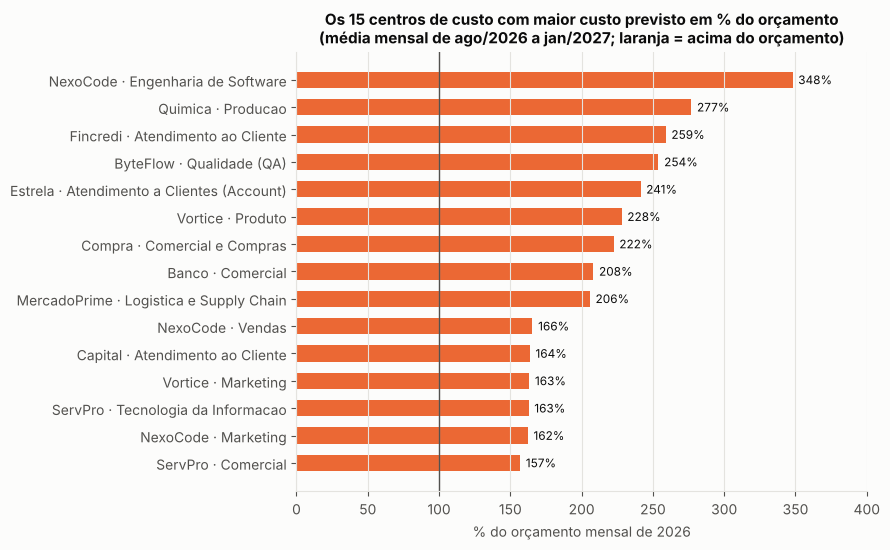

In [18]:
top = cc.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.6))
cores_sit = {'Acima do orçamento': LARANJA, 'Risco: acima no cenário de 90%': AMARELO, 'Atenção: entre 90% e 100%': AMARELO, 'Dentro do orçamento': AZUL}
rotulos = [f"{n.split()[0]} · {d}" for n, d in zip(top.company_name, top.departamento)]
ax.barh(rotulos, top.uso_do_orcamento * 100, color=[cores_sit[x] for x in top.situacao], height=0.6)
ax.axvline(100, color=TINTA2, lw=1)
for i, v in enumerate(top.uso_do_orcamento * 100):
    ax.text(v + 4, i, f'{v:.0f}%', va='center', fontsize=8.5, color=TINTA)
ax.set(title='Os 15 centros de custo com maior custo previsto em % do orçamento\n(média mensal de ago/2026 a jan/2027; laranja = acima do orçamento)',
       xlabel='% do orçamento mensal de 2026', xlim=(0, top.uso_do_orcamento.max() * 115))
ax.grid(axis='y', visible=False)
fig.tight_layout(); fig.savefig(FIG / 'fig5_orcamento_centros_de_custo.png', dpi=150); plt.show()

## 9. Conclusões

Os números abaixo saem das tabelas acima.

In [19]:
v = tabela_val
print(f"Modelo escolhido para a demanda: {ESCOLHIDO} — WAPE {v.loc[ESCOLHIDO, 'WAPE h=1']:.1%} (1 mês), {v.loc[ESCOLHIDO, 'WAPE h=2']:.1%} (2), "
      f"{v.loc[ESCOLHIDO, 'WAPE h=3']:.1%} (3); ingênuo: {v.loc['Ingênuo', 'WAPE h=1']:.1%}, {v.loc['Ingênuo', 'WAPE h=2']:.1%}, {v.loc['Ingênuo', 'WAPE h=3']:.1%}")
print(f"Viés do modelo escolhido: {v.loc[ESCOLHIDO, 'viés']:+.1%} | cobertura da faixa de 80% fora da calibração: {aval.dentro.mean():.0%}")
print(f"Demanda total prevista: ago/2026 {tot_prev.iloc[0] / 1e3:,.0f} mil, dez/2026 {tot_prev.loc['2026-12'] / 1e3:,.0f} mil, jan/2027 {tot_prev.loc['2027-01'] / 1e3:,.0f} mil "
      f"(jul/2026 real: {tot_hist.iloc[-1] / 1e3:,.0f} mil)")
print(f"Tokens de consumo: modelo {METODO_TOK}, WAPE {geral_tok.loc[METODO_TOK, 'WAPE']:.1%} (ingênuo {geral_tok.loc['Ingênuo', 'WAPE']:.1%})")
print(f"Centros de custo acima do orçamento: {(cc.situacao == 'Acima do orçamento').sum()} de {len(cc)}; maior: {cc.iloc[0].company_name} · {cc.iloc[0].departamento} ({cc.iloc[0].uso_do_orcamento:.0%})")
print('Empresas com custo total acima do orçamento somado:', emp_orc[emp_orc.uso_do_orcamento > 1].index.get_level_values(1).tolist())
print(f'Tempo total: {time.time() - inicio:.0f} s')

Modelo escolhido para a demanda: Tendência × fatores comuns — WAPE 5.8% (1 mês), 5.6% (2), 6.1% (3); ingênuo: 12.8%, 18.6%, 22.4%
Viés do modelo escolhido: -1.1% | cobertura da faixa de 80% fora da calibração: 89%
Demanda total prevista: ago/2026 979 mil, dez/2026 670 mil, jan/2027 972 mil (jul/2026 real: 792 mil)
Tokens de consumo: modelo Tendência + férias, WAPE 14.7% (ingênuo 25.2%)
Centros de custo acima do orçamento: 35 de 161; maior: NexoCode Solucoes · Engenharia de Software (348%)
Empresas com custo total acima do orçamento somado: ['ServPro Facilities', 'Banco Alterosa S.A.']
Tempo total: 12 s


### Resumo

| Entrega | Resultado |
|---|---|
| Modelo de demanda | Tendência linear por empresa × fatores de calendário comuns (dezembro 0,58, janeiro 0,81, julho 0,86) |
| Validação | Backtest com 7 origens, 18 empresas e horizontes de 1 a 3 meses. WAPE de 5,8%, contra 17,5% do ingênuo e 16,5% do gradient boosting global; viés de −1,1% |
| Intervalos | Faixa de 80% calibrada no backtest, com cobertura de 89% fora da calibração |
| Previsão | 979 mil requisições em ago/2026, 1,11 milhão em nov/2026, 670 mil em dez/2026 e 972 mil em jan/2027 |
| Custo | O consumo é menos de 2% do custo; os tokens são previstos com WAPE de 14,7% |
| Orçamento | 35 de 161 centros de custo acima do orçamento (R$ 84 mil por mês). O maior é Engenharia de Software da NexoCode, com 348% |

**Limitações**
- Há só 14 meses de histórico e um ciclo anual. Os fatores de dezembro e janeiro vêm de uma única observação por empresa, e a validação vai até 3 meses à frente. De 4 a 6 meses, a faixa é extrapolada.
- A base é sintética. Tendência e calendário seguem regras simples na geração, o que favorece modelos com essa mesma estrutura. Dados reais terão choques (lançamento de ferramenta, mudança de preço) que nenhum desses modelos antecipa.
- Os assentos são projetados como constantes. Renovação, expiração e realocação de contratos mudam esse valor, e a base registra só o status atual de cada licença.

**Próximo passo no produto:** a previsão por centro de custo pode virar o alerta "orçamento de IA em risco" nas análises de gestão do DAMA. O orçamento previsto também pode entrar na restrição R1 da Pesquisa Operacional no lugar da média histórica.